# CME519 Data Mining — Midterm Project
## Notebook 3 — Modeling & Evaluation

**Student:** Musa AL AHMED (26221001014) · **Dataset:** AIDev (hao-li/AIDev)

CRISP-DM phases 4–5. Input: `data/model_data.parquet` and `data/prep_config.json` from Notebook 2.

**Plan**

1. Re-create the same preprocessing pipeline (fitted on training folds only).
2. Compare a **baseline** and four models taught in the course — **KNN, Logistic Regression, Decision Tree, Random Forest** — with **5-fold stratified cross-validation** on the training set.
3. Choose the best model by **PR-AUC of the rejected class**, refit it on the whole training set and evaluate it **once** on the untouched test set (confusion matrix, ROC and PR curves).
4. Explain the model with **permutation importance**.
5. **Leakage check:** repeat the evaluation without the commit-based features.

## 1. Setup and data

In [2]:
import os, sys, json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, recall_score, precision_score, f1_score,
                             balanced_accuracy_score, accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK_DIR = "/content/drive/MyDrive/CME519_AIDev"
else:
    WORK_DIR = os.environ.get("AIDEV_WORK_DIR", os.path.abspath("CME519_AIDev"))
DATA_DIR = os.path.join(WORK_DIR, "data"); FIG_DIR = os.path.join(WORK_DIR, "figures")
def save_fig(name):
    p = os.path.join(FIG_DIR, f"{name}.png"); plt.savefig(p, dpi=150, bbox_inches="tight"); print("figure saved ->", p)

data = pd.read_parquet(os.path.join(DATA_DIR, "model_data.parquet"))
cfg = json.load(open(os.path.join(DATA_DIR, "prep_config.json")))
NUM_FEATURES, CAT_FEATURES = cfg["NUM_FEATURES"], cfg["CAT_FEATURES"]
COMMIT_FEATURES, BEST_OUTLIER = cfg["COMMIT_FEATURES"], cfg["BEST_OUTLIER"]
BEST_FS, BEST_FS_COLUMNS, RANDOM_STATE = cfg["BEST_FS"], cfg["BEST_FS_COLUMNS"], cfg["RANDOM_STATE"]

train, test = data[data["split"] == "train"], data[data["split"] == "test"]
FEATS = NUM_FEATURES + CAT_FEATURES
X_train, y_train = train[FEATS], train["merged"].astype(int)
X_test, y_test = test[FEATS], test["merged"].astype(int)
print(f"Train: {len(X_train):,} rows | Test: {len(X_test):,} rows | features: {len(FEATS)}")
print(f"Rejected share (positive class for PR-AUC): train {1-y_train.mean():.3f} | test {1-y_test.mean():.3f}")
print(f"Outlier strategy from Notebook 2: {BEST_OUTLIER} | feature set: {BEST_FS} ({len(BEST_FS_COLUMNS)} columns)")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Train: 265,924 rows | Test: 66,482 rows | features: 38
Rejected share (positive class for PR-AUC): train 0.258 | test 0.258
Outlier strategy from Notebook 2: log | feature set: Embedded: L1 LogReg (64 columns)


## 2. Pipeline components (same definitions as Notebook 2)

In [3]:
class QuantileCapper(BaseEstimator, TransformerMixin):
    def __init__(self, low=0.01, high=0.99):
        self.low, self.high = low, high
    def fit(self, X, y=None):
        X = pd.DataFrame(X); self.lo_ = X.quantile(self.low).values; self.hi_ = X.quantile(self.high).values
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype=float), self.lo_, self.hi_)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)

def signed_log1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

def make_preprocessor(outlier=BEST_OUTLIER, num=None, cat=None):
    num = NUM_FEATURES if num is None else num; cat = CAT_FEATURES if cat is None else cat
    steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
    if outlier in ("cap", "log_cap"):
        steps.append(("cap", QuantileCapper(0.01, 0.99)))
    if outlier in ("log", "log_cap"):
        steps.append(("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")))
    steps.append(("scale", StandardScaler()))
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                         ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01, sparse_output=False))])
    return ColumnTransformer([("num", Pipeline(steps), num), ("cat", cat_pipe, cat)],
                             verbose_feature_names_out=False).set_output(transform="pandas")

class NameSelector(BaseEstimator, TransformerMixin):
    def __init__(self, columns=None):
        self.columns = columns
    def fit(self, X, y=None):
        self.cols_ = list(X.columns) if self.columns is None else [c for c in self.columns if c in X.columns]
        return self
    def transform(self, X):
        return X.reindex(columns=self.cols_, fill_value=0.0).values

def make_pipe(model, columns=BEST_FS_COLUMNS, num=None, cat=None):
    return Pipeline([("pre", make_preprocessor(num=num, cat=cat)), ("select", NameSelector(columns)), ("clf", model)])

def proba_rejected(est, X):
    return est.predict_proba(X)[:, list(est.classes_).index(0)]
def ap_rejected(est, X, y):
    return average_precision_score((np.asarray(y) == 0).astype(int), proba_rejected(est, X))
def recall_rejected(est, X, y):
    return recall_score(y, est.predict(X), pos_label=0)
def precision_rejected(est, X, y):
    return precision_score(y, est.predict(X), pos_label=0, zero_division=0)

SCORING = {"pr_auc_rejected": ap_rejected, "roc_auc": "roc_auc", "f1_macro": "f1_macro",
           "balanced_accuracy": "balanced_accuracy", "recall_rejected": recall_rejected,
           "precision_rejected": precision_rejected}
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
print("Metrics:", list(SCORING))

Metrics: ['pr_auc_rejected', 'roc_auc', 'f1_macro', 'balanced_accuracy', 'recall_rejected', 'precision_rejected']


## 3. Choosing K for KNN (5-fold CV, GridSearchCV)

KNN stores the whole training set and computes a distance to every stored point for each prediction, so prediction cost grows with the data size. K is tuned on a stratified sample of 30,000 training PRs; small K overfits (high variance), very large K underfits (high bias).

,K,weights,PR-AUC (rejected),std
5,31,distance,0.5752,0.0126
7,51,distance,0.5746,0.0121
9,101,distance,0.5716,0.0127
3,15,distance,0.5660,0.0082
8,101,uniform,0.5571,0.0122
6,51,uniform,0.5561,0.0125
4,31,uniform,0.5517,0.0129
2,15,uniform,0.5329,0.0085
1,5,distance,0.5304,0.0059
0,5,uniform,0.4834,0.0051


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/15_knn_choose_k.png


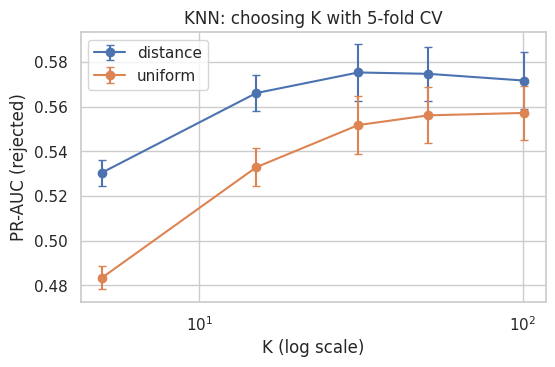

Best K = 31 (distance) in 98s. Interpretation: very small K follows noise (overfitting); performance improves as K grows and then flattens/decreases when K becomes too large (underfitting).


In [4]:
n_k = min(30_000, len(X_train))
Xk, _, yk, _ = train_test_split(X_train, y_train, train_size=n_k, stratify=y_train, random_state=RANDOM_STATE) \
    if n_k < len(X_train) else (X_train, None, y_train, None)
grid = GridSearchCV(make_pipe(KNeighborsClassifier()),
                    {"clf__n_neighbors": [5, 15, 31, 51, 101], "clf__weights": ["uniform", "distance"]},
                    scoring=ap_rejected, cv=CV, n_jobs=-1)
t0 = time.time(); grid.fit(Xk, yk)
kres = pd.DataFrame(grid.cv_results_)[["param_clf__n_neighbors", "param_clf__weights", "mean_test_score", "std_test_score"]]
kres.columns = ["K", "weights", "PR-AUC (rejected)", "std"]
display(kres.sort_values("PR-AUC (rejected)", ascending=False).round(4))
BEST_K = grid.best_params_["clf__n_neighbors"]; BEST_W = grid.best_params_["clf__weights"]

fig, ax = plt.subplots(figsize=(6, 3.5))
for w, g in kres.groupby("weights"):
    ax.errorbar(g["K"], g["PR-AUC (rejected)"], yerr=g["std"], marker="o", capsize=3, label=w)
ax.set_xscale("log"); ax.set_xlabel("K (log scale)"); ax.set_ylabel("PR-AUC (rejected)"); ax.legend()
ax.set_title("KNN: choosing K with 5-fold CV")
save_fig("15_knn_choose_k"); plt.show()
print(f"Best K = {BEST_K} ({BEST_W}) in {time.time()-t0:.0f}s. Interpretation: very small K follows noise (overfitting); "
      f"performance improves as K grows and then flattens/decreases when K becomes too large (underfitting).")

## 4. Model comparison — 5-fold stratified cross-validation on the training set

| Model | Notes |
|---|---|
| Baseline (stratified random) | lower bound: predicts with the class ratio only |
| KNN | best K from Section 3; trained on a 60,000-PR stratified sample because prediction cost grows with data size |
| Logistic Regression | linear, `class_weight="balanced"` for the imbalance |
| Decision Tree | `max_depth=10`, `min_samples_leaf=50`, balanced weights |
| Random Forest | 200 trees, `max_depth=16`, `min_samples_leaf=5`, balanced weights |

Same folds for all models; preprocessing and feature selection are inside the pipeline.

In [5]:
n_knn = min(60_000, len(X_train))
X_knn, _, y_knn, _ = train_test_split(X_train, y_train, train_size=n_knn, stratify=y_train, random_state=RANDOM_STATE) \
    if n_knn < len(X_train) else (X_train, None, y_train, None)

MODELS = {
    "Baseline (stratified)": (DummyClassifier(strategy="stratified", random_state=RANDOM_STATE), "full"),
    f"KNN (K={BEST_K}, {BEST_W})": (KNeighborsClassifier(n_neighbors=BEST_K, weights=BEST_W), "knn_sample"),
    "Logistic Regression": (LogisticRegression(max_iter=3000, class_weight="balanced"), "full"),
    "Decision Tree": (DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced",
                                             random_state=RANDOM_STATE), "full"),
    "Random Forest": (RandomForestClassifier(n_estimators=200, max_depth=16, min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=-1, random_state=RANDOM_STATE), "full"),
}
cv_rows, cv_raw = [], {}
for name, (mdl, data_kind) in MODELS.items():
    Xd, yd = (X_knn, y_knn) if data_kind == "knn_sample" else (X_train, y_train)
    t0 = time.time()
    r = cross_validate(make_pipe(mdl), Xd, yd, scoring=SCORING, cv=CV, n_jobs=1 if "Forest" in name else -1)
    cv_raw[name] = r
    row = {"model": name, "train_rows": len(Xd)}
    for m in SCORING:
        row[m] = r[f"test_{m}"].mean(); row[m + "_std"] = r[f"test_{m}"].std()
    row["fit_time_s"] = r["fit_time"].mean(); row["predict_time_s"] = r["score_time"].mean()
    cv_rows.append(row)
    print(f"{name:<28} PR-AUC(rej)={row['pr_auc_rejected']:.4f}±{row['pr_auc_rejected_std']:.4f}  "
          f"ROC-AUC={row['roc_auc']:.4f}  ({time.time()-t0:.0f}s)")
cv_tbl = pd.DataFrame(cv_rows).set_index("model")

Baseline (stratified)        PR-AUC(rej)=0.2577±0.0008  ROC-AUC=0.5003  (22s)
KNN (K=31, distance)         PR-AUC(rej)=0.5948±0.0100  ROC-AUC=0.7622  (151s)
Logistic Regression          PR-AUC(rej)=0.5770±0.0028  ROC-AUC=0.7527  (32s)
Decision Tree                PR-AUC(rej)=0.5935±0.0027  ROC-AUC=0.7643  (38s)
Random Forest                PR-AUC(rej)=0.6736±0.0022  ROC-AUC=0.8157  (529s)


5-fold stratified CV on the training set (mean ± std)


,pr_auc_rejected,roc_auc,f1_macro,balanced_accuracy,recall_rejected,precision_rejected,fit_time_s,predict_time_s,train_rows
model,,,,,,,,,
Random Forest,0.6736 ± 0.0022,0.8157 ± 0.0016,0.7194 ± 0.0023,0.7290 ± 0.0022,0.6307 ± 0.0037,0.5590 ± 0.0040,95.587168,10.124552,265924
"KNN (K=31, distance)",0.5948 ± 0.0100,0.7622 ± 0.0055,0.6361 ± 0.0066,0.6205 ± 0.0050,0.2686 ± 0.0088,0.7717 ± 0.0171,1.233980,52.073144,60000
Decision Tree,0.5935 ± 0.0027,0.7643 ± 0.0020,0.6589 ± 0.0074,0.6891 ± 0.0026,0.6568 ± 0.0248,0.4508 ± 0.0132,11.174962,1.946911,265924
Logistic Regression,0.5770 ± 0.0028,0.7527 ± 0.0018,0.6495 ± 0.0010,0.6823 ± 0.0011,0.6595 ± 0.0015,0.4369 ± 0.0012,9.140008,2.002209,265924
Baseline (stratified),0.2577 ± 0.0008,0.5003 ± 0.0021,0.5003 ± 0.0021,0.5003 ± 0.0021,0.2561 ± 0.0032,0.2580 ± 0.0032,5.110214,2.323544,265924


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/16_model_comparison_cv.png


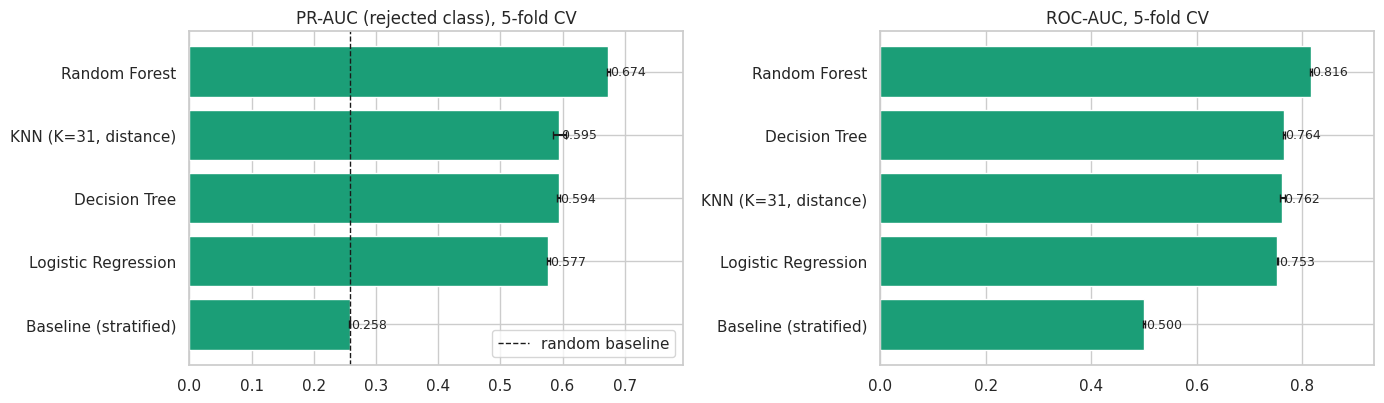

Interpretation: best model by PR-AUC of the rejected class = Random Forest (0.6736 vs baseline 0.2577). Fold standard deviation 0.0022 (stable across folds). KNN has the highest prediction time per fold even on a smaller sample, which matches its lazy-learning nature.


In [6]:
show = ["pr_auc_rejected", "roc_auc", "f1_macro", "balanced_accuracy", "recall_rejected", "precision_rejected",
        "fit_time_s", "predict_time_s", "train_rows"]
report_tbl = cv_tbl[show].copy()
for m in ["pr_auc_rejected", "roc_auc", "f1_macro", "balanced_accuracy", "recall_rejected", "precision_rejected"]:
    report_tbl[m] = cv_tbl[m].map("{:.4f}".format) + " ± " + cv_tbl[m + "_std"].map("{:.4f}".format)
print("5-fold stratified CV on the training set (mean ± std)")
display(report_tbl.sort_values("pr_auc_rejected", ascending=False))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, m, title in [(axes[0], "pr_auc_rejected", "PR-AUC (rejected class)"), (axes[1], "roc_auc", "ROC-AUC")]:
    order = cv_tbl.sort_values(m).index
    ax.barh(order, cv_tbl.loc[order, m], xerr=cv_tbl.loc[order, m + "_std"], color="#1b9e77", capsize=3)
    for i, v in enumerate(cv_tbl.loc[order, m]):
        ax.text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
    ax.set_title(f"{title}, 5-fold CV"); ax.set_xlim(0, min(1, cv_tbl[m].max() + 0.12))
axes[0].axvline(1 - y_train.mean(), ls="--", c="k", lw=1, label="random baseline"); axes[0].legend(loc="lower right")
plt.tight_layout(); save_fig("16_model_comparison_cv"); plt.show()

BEST_MODEL = cv_tbl.drop(index="Baseline (stratified)")["pr_auc_rejected"].idxmax()
print(f"Interpretation: best model by PR-AUC of the rejected class = {BEST_MODEL} "
      f"({cv_tbl.loc[BEST_MODEL, 'pr_auc_rejected']:.4f} vs baseline {cv_tbl.loc['Baseline (stratified)', 'pr_auc_rejected']:.4f}). "
      f"Fold standard deviation {cv_tbl.loc[BEST_MODEL, 'pr_auc_rejected_std']:.4f} "
      f"({'stable' if cv_tbl.loc[BEST_MODEL, 'pr_auc_rejected_std'] < 0.01 else 'some variation'} across folds). "
      f"KNN has the highest prediction time per fold even on a smaller sample, which matches its lazy-learning nature.")

## 5. Final evaluation on the untouched test set

The selected model is refitted on the **whole training set** and evaluated **once** on the 20% test set.

In [7]:
best_est, kind = MODELS[BEST_MODEL]
X_fit, y_fit = (X_knn, y_knn) if kind == "knn_sample" else (X_train, y_train)
final = make_pipe(best_est).fit(X_fit, y_fit)
p_rej = proba_rejected(final, X_test); y_pred = final.predict(X_test)

test_metrics = {
    "PR-AUC (rejected)": average_precision_score((y_test == 0).astype(int), p_rej),
    "ROC-AUC": roc_auc_score(y_test, 1 - p_rej),
    "F1 macro": f1_score(y_test, y_pred, average="macro"),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_pred),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Recall (rejected)": recall_score(y_test, y_pred, pos_label=0),
    "Precision (rejected)": precision_score(y_test, y_pred, pos_label=0),
}
display(pd.Series(test_metrics, name=f"{BEST_MODEL} — test set").round(4).to_frame())
print(classification_report(y_test, y_pred, target_names=["0 = not merged", "1 = merged"], digits=3))
print(f"Interpretation: test PR-AUC {test_metrics['PR-AUC (rejected)']:.4f} vs CV {cv_tbl.loc[BEST_MODEL,'pr_auc_rejected']:.4f} "
      + ("-> close values: the model generalises to unseen PRs." if abs(test_metrics['PR-AUC (rejected)'] - cv_tbl.loc[BEST_MODEL,'pr_auc_rejected']) < 0.02
         else "-> the gap shows some variance between data subsets; reported honestly in the report."))

,Random Forest — test set
PR-AUC (rejected),0.6741
ROC-AUC,0.8155
F1 macro,0.7180
Balanced accuracy,0.7295
Accuracy,0.7739
Recall (rejected),0.6380
Precision (rejected),0.5529


                precision    recall  f1-score   support

0 = not merged      0.553     0.638     0.592     17126
    1 = merged      0.867     0.821     0.844     49356

      accuracy                          0.774     66482
     macro avg      0.710     0.730     0.718     66482
  weighted avg      0.786     0.774     0.779     66482

Interpretation: test PR-AUC 0.6741 vs CV 0.6736 -> close values: the model generalises to unseen PRs.


figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/17_confusion_matrix.png


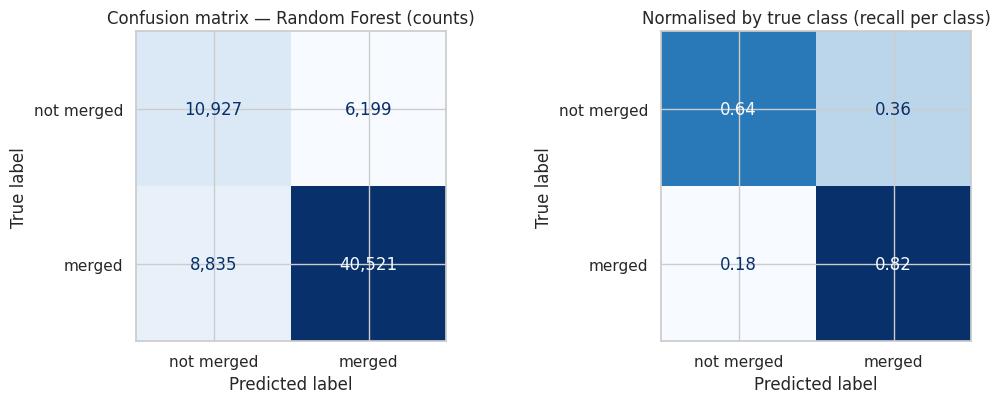

Interpretation: 10,927 of 17,126 rejected PRs are correctly flagged (63.8%); 8,835 merged PRs are wrongly flagged as rejected (17.9% of merged PRs).


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
ConfusionMatrixDisplay(cm, display_labels=["not merged", "merged"]).plot(ax=axes[0], cmap="Blues", values_format=",d", colorbar=False)
axes[0].set_title(f"Confusion matrix — {BEST_MODEL} (counts)")
cmn = confusion_matrix(y_test, y_pred, labels=[0, 1], normalize="true")
ConfusionMatrixDisplay(cmn, display_labels=["not merged", "merged"]).plot(ax=axes[1], cmap="Blues", values_format=".2f", colorbar=False)
axes[1].set_title("Normalised by true class (recall per class)")
plt.tight_layout(); save_fig("17_confusion_matrix"); plt.show()
tn, fp, fn, tp = cm[0, 0], cm[0, 1], cm[1, 0], cm[1, 1]
print(f"Interpretation: {tn:,} of {tn+fp:,} rejected PRs are correctly flagged ({tn/(tn+fp):.1%}); "
      f"{fn:,} merged PRs are wrongly flagged as rejected ({fn/(fn+tp):.1%} of merged PRs).")

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/18_roc_pr_curves.png


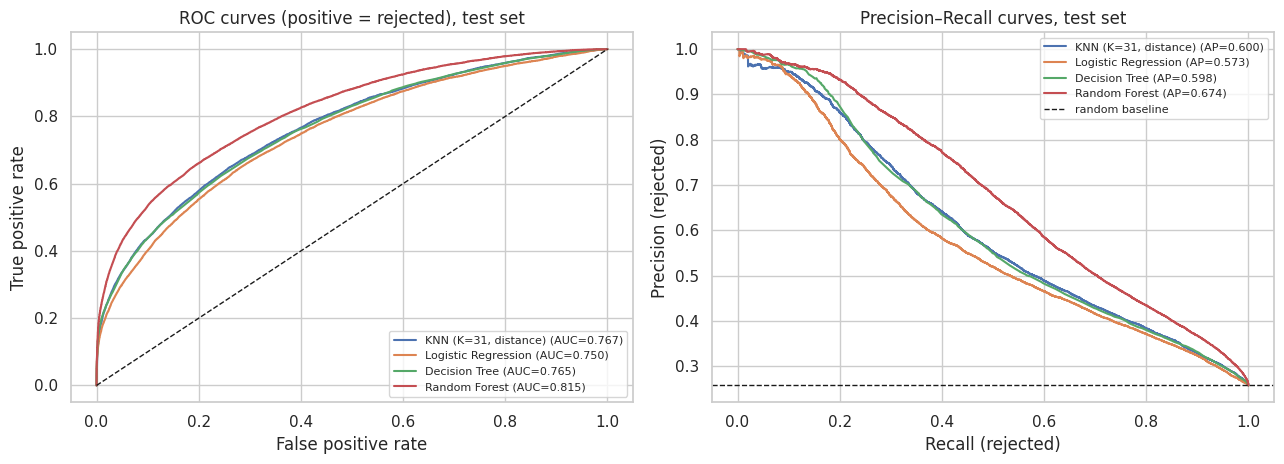

Interpretation: the PR curve shows the trade-off for the rejected class — flagging more PRs (higher recall) lowers precision. The decision threshold (0.5 here) will be tuned in the final project.


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, (mdl, kind) in MODELS.items():
    if name.startswith("Baseline"):
        continue
    Xf, yf = (X_knn, y_knn) if kind == "knn_sample" else (X_train, y_train)
    est = final if name == BEST_MODEL else make_pipe(mdl).fit(Xf, yf)
    pr = proba_rejected(est, X_test); yt = (y_test == 0).astype(int)
    fpr, tpr, _ = roc_curve(yt, pr); prec, rec, _ = precision_recall_curve(yt, pr)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(yt, pr):.3f})")
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(yt, pr):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1); axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate")
axes[0].set_title("ROC curves (positive = rejected), test set"); axes[0].legend(fontsize=8)
axes[1].axhline((y_test == 0).mean(), ls="--", c="k", lw=1, label="random baseline")
axes[1].set_xlabel("Recall (rejected)"); axes[1].set_ylabel("Precision (rejected)")
axes[1].set_title("Precision–Recall curves, test set"); axes[1].legend(fontsize=8)
plt.tight_layout(); save_fig("18_roc_pr_curves"); plt.show()
print("Interpretation: the PR curve shows the trade-off for the rejected class — flagging more PRs (higher recall) "
      "lowers precision. The decision threshold (0.5 here) will be tuned in the final project.")

## 6. Which features matter? — permutation importance

Each original feature is shuffled on (a sample of) the test set; the drop in PR-AUC shows how much the model relies on it. This works on the whole pipeline, so one-hot columns are grouped back to their original feature.

figure saved -> /content/drive/MyDrive/CME519_AIDev/figures/19_permutation_importance.png


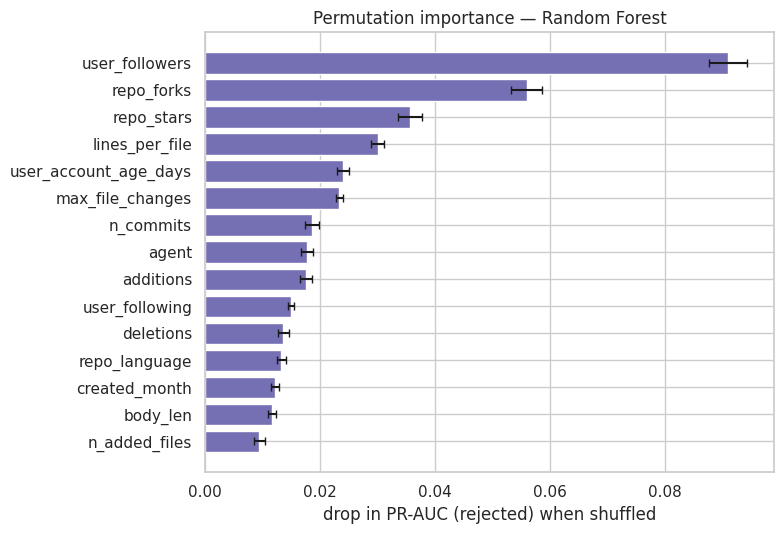

,feature,importance,std
2,user_followers,0.0910,0.0033
0,repo_forks,0.0560,0.0027
1,repo_stars,0.0357,0.0021
29,lines_per_file,0.0300,0.0011
21,user_account_age_days,0.0239,0.0010
15,max_file_changes,0.0233,0.0006
4,n_commits,0.0185,0.0012
34,agent,0.0177,0.0010
6,additions,0.0175,0.0010
3,user_following,0.0149,0.0006


(137s) Interpretation: the top features are the main drivers of the merge decision; features near zero could be dropped without loss.


In [10]:
n_pi = min(15_000, len(X_test))
Xp, _, yp, _ = train_test_split(X_test, y_test, train_size=n_pi, stratify=y_test, random_state=RANDOM_STATE) \
    if n_pi < len(X_test) else (X_test, None, y_test, None)
t0 = time.time()
pi = permutation_importance(final, Xp, yp, scoring=ap_rejected, n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
imp = pd.DataFrame({"feature": Xp.columns, "importance": pi.importances_mean, "std": pi.importances_std})
imp = imp.sort_values("importance", ascending=False)
top = imp.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(top["feature"], top["importance"], xerr=top["std"], color="#7570b3", capsize=3)
ax.set_xlabel("drop in PR-AUC (rejected) when shuffled"); ax.set_title(f"Permutation importance — {BEST_MODEL}")
plt.tight_layout(); save_fig("19_permutation_importance"); plt.show()
display(imp.head(15).round(4))
print(f"({time.time()-t0:.0f}s) Interpretation: the top features are the main drivers of the merge decision; "
      "features near zero could be dropped without loss.")

## 7. Leakage / robustness check — without commit-based features

Commit and file statistics may include commits pushed **after** review feedback, which could leak information about the outcome. The best model is evaluated again (5-fold CV) using only features that are certainly known when the PR is opened (agent, repository, author, title/description, creation time).

In [11]:
safe_num = [c for c in NUM_FEATURES if c not in COMMIT_FEATURES]
abl_mdl, kind = MODELS[BEST_MODEL]
Xd, yd = (X_knn, y_knn) if kind == "knn_sample" else (X_train, y_train)
t0 = time.time()
r_safe = cross_validate(make_pipe(abl_mdl, columns=None, num=safe_num), Xd[safe_num + CAT_FEATURES], yd,
                        scoring=SCORING, cv=CV, n_jobs=1 if "Forest" in BEST_MODEL else -1)
abl = pd.DataFrame({
    "with commit features": [cv_tbl.loc[BEST_MODEL, m] for m in ["pr_auc_rejected", "roc_auc", "f1_macro"]],
    "without commit features": [r_safe[f"test_{m}"].mean() for m in ["pr_auc_rejected", "roc_auc", "f1_macro"]],
}, index=["PR-AUC (rejected)", "ROC-AUC", "F1 macro"]).round(4)
abl["difference"] = (abl["without commit features"] - abl["with commit features"]).round(4)
display(abl)
d = abl.loc["PR-AUC (rejected)", "difference"]
print(f"({time.time()-t0:.0f}s) Interpretation: removing commit-based features changes PR-AUC by {d:+.4f}. "
      + ("The model keeps most of its performance, so the results do not depend on possibly-leaky commit information."
         if abs(d) < 0.03 else
         "The drop is noticeable: part of the signal comes from commit/file statistics, so the final project will "
         "restrict them to commits made before the first review (using the timeline table)."))

,with commit features,without commit features,difference
PR-AUC (rejected),0.6736,0.6090,-0.0646
ROC-AUC,0.8157,0.7968,-0.0189
F1 macro,0.7194,0.6812,-0.0382


(387s) Interpretation: removing commit-based features changes PR-AUC by -0.0646. The drop is noticeable: part of the signal comes from commit/file statistics, so the final project will restrict them to commits made before the first review (using the timeline table).


## 8. Summary for the report

In [12]:
res = cv_tbl[["pr_auc_rejected", "pr_auc_rejected_std", "roc_auc", "f1_macro", "recall_rejected", "precision_rejected"]].round(4)
res.to_csv(os.path.join(DATA_DIR, "cv_model_results.csv"))
pd.Series(test_metrics).to_csv(os.path.join(DATA_DIR, "test_metrics.csv"))
imp.to_csv(os.path.join(DATA_DIR, "permutation_importance.csv"), index=False)
abl.to_csv(os.path.join(DATA_DIR, "leakage_ablation.csv"))

print("DATA      :", f"{len(X_train):,} train / {len(X_test):,} test PRs; rejected share {1-y_train.mean():.1%}")
print("FEATURES  :", f"{len(FEATS)} inputs -> {BEST_FS} -> {len(BEST_FS_COLUMNS)} columns; outliers: {BEST_OUTLIER}")
print("CV (5-fold, PR-AUC rejected):")
for m, v in cv_tbl["pr_auc_rejected"].sort_values(ascending=False).items():
    print(f"   {m:<28} {v:.4f} ± {cv_tbl.loc[m, 'pr_auc_rejected_std']:.4f} | ROC-AUC {cv_tbl.loc[m, 'roc_auc']:.4f}")
print("BEST      :", BEST_MODEL)
print("TEST      :", ", ".join(f"{k} {v:.3f}" for k, v in test_metrics.items()))
print("TOP-5 FEATURES:", ", ".join(imp["feature"].head(5)))
print("LEAKAGE CHECK : PR-AUC without commit features", f"{abl.loc['PR-AUC (rejected)', 'without commit features']:.4f}",
      f"({abl.loc['PR-AUC (rejected)', 'difference']:+.4f})")
print("FINAL PROJECT : hyperparameter tuning, decision-threshold tuning, more models, CleanLens code-quality features.")

DATA      : 265,924 train / 66,482 test PRs; rejected share 25.8%
FEATURES  : 38 inputs -> Embedded: L1 LogReg -> 64 columns; outliers: log
CV (5-fold, PR-AUC rejected):
   Random Forest                0.6736 ± 0.0022 | ROC-AUC 0.8157
   KNN (K=31, distance)         0.5948 ± 0.0100 | ROC-AUC 0.7622
   Decision Tree                0.5935 ± 0.0027 | ROC-AUC 0.7643
   Logistic Regression          0.5770 ± 0.0028 | ROC-AUC 0.7527
   Baseline (stratified)        0.2577 ± 0.0008 | ROC-AUC 0.5003
BEST      : Random Forest
TEST      : PR-AUC (rejected) 0.674, ROC-AUC 0.815, F1 macro 0.718, Balanced accuracy 0.730, Accuracy 0.774, Recall (rejected) 0.638, Precision (rejected) 0.553
TOP-5 FEATURES: user_followers, repo_forks, repo_stars, lines_per_file, user_account_age_days
LEAKAGE CHECK : PR-AUC without commit features 0.6090 (-0.0646)
FINAL PROJECT : hyperparameter tuning, decision-threshold tuning, more models, CleanLens code-quality features.


## 9. Package figures and result tables (for the report)

In [13]:
import shutil
zip_base = os.path.join("/content" if IN_COLAB else WORK_DIR, "CME519_results")
tmp = zip_base + "_dir"
shutil.rmtree(tmp, ignore_errors=True); os.makedirs(tmp)
shutil.copytree(FIG_DIR, os.path.join(tmp, "figures"))
os.makedirs(os.path.join(tmp, "data"))
for f in os.listdir(DATA_DIR):
    if f.endswith((".csv", ".json")):
        shutil.copy(os.path.join(DATA_DIR, f), os.path.join(tmp, "data", f))
zip_path = shutil.make_archive(zip_base, "zip", tmp)
print("Created", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB):", sorted(os.listdir(os.path.join(tmp, "figures"))))
if IN_COLAB:
    from google.colab import files
    files.download(zip_path)

Created /content/CME519_results.zip (1.8 MB): ['01_target_distribution.png', '02_missing_values.png', '03_numeric_distributions_by_class.png', '04_boxplots_by_class.png', '05_merge_rate_agent_language.png', '06_temporal_patterns.png', '07_text_features.png', '08_correlation_heatmap.png', '09_scatter_additions_deletions.png', '10_leakage_time_to_close.png', '11_engineered_features_vs_target.png', '12_imputation_effect.png', '13_outlier_strategies.png', '14_feature_selection_comparison.png', '15_knn_choose_k.png', '16_model_comparison_cv.png', '17_confusion_matrix.png', '18_roc_pr_curves.png', '19_permutation_importance.png']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>